In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
folder = "data/raw/UCI HAR Dataset"

channels = ["total_acc_x", "total_acc_y", "total_acc_z",
            "body_acc_x",  "body_acc_y",  "body_acc_z",
            "body_gyro_x", "body_gyro_y", "body_gyro_z"]

signals = []

for c in channels:
    table = np.loadtxt(folder + "/train/Inertial Signals/" + c + "_train.txt")
    signals.append(table)

# print(len(signals[0][0]))

W = np.stack(signals, axis = 2)
print(W.shape)


(7352, 128, 9)


In [3]:
y = np.loadtxt(folder + "/train/y_train.txt", dtype=int)
person = np.loadtxt(folder + "/train/subject_train.txt", dtype=int)
names = {1: "walking", 2: "upstairs", 3: "downstairs", 4: "sitting", 5: "standing", 6: "lying"}

print(y.shape, person.shape)
print("window 0:", names[y[0]], "by person", person[0])
print("window 78:", names[y[78]], "by person", person[78])

(7352,) (7352,)
window 0: standing by person 1
window 78: walking by person 1


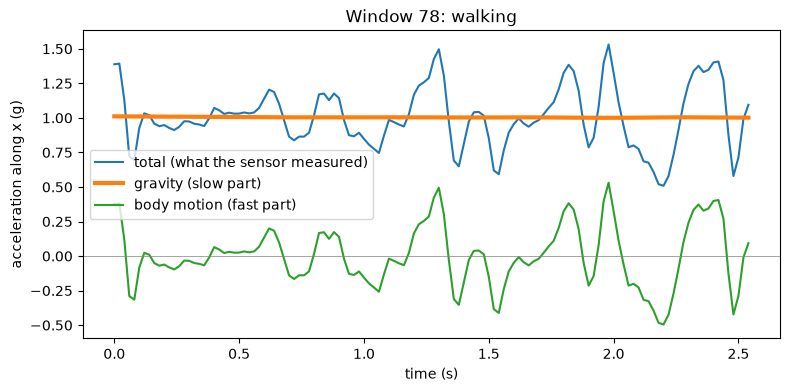

In [7]:
i = 78
total = W[i, :, 0]
body = W[i, :, 3]
gravity = total - body

t = np.arange(128) / 50

plt.figure(figsize=(9, 4))
plt.plot(t, total, label="total (what the sensor measured)")
plt.plot(t, gravity, label="gravity (slow part)", linewidth=3)
plt.plot(t, body, label="body motion (fast part)")
plt.axhline(0, color="grey", linewidth=0.5)
plt.xlabel("time (s)")
plt.ylabel("acceleration along x (g)")
plt.legend()
plt.title("Window " + str(i) + ": " + names[y[i]])
plt.show()

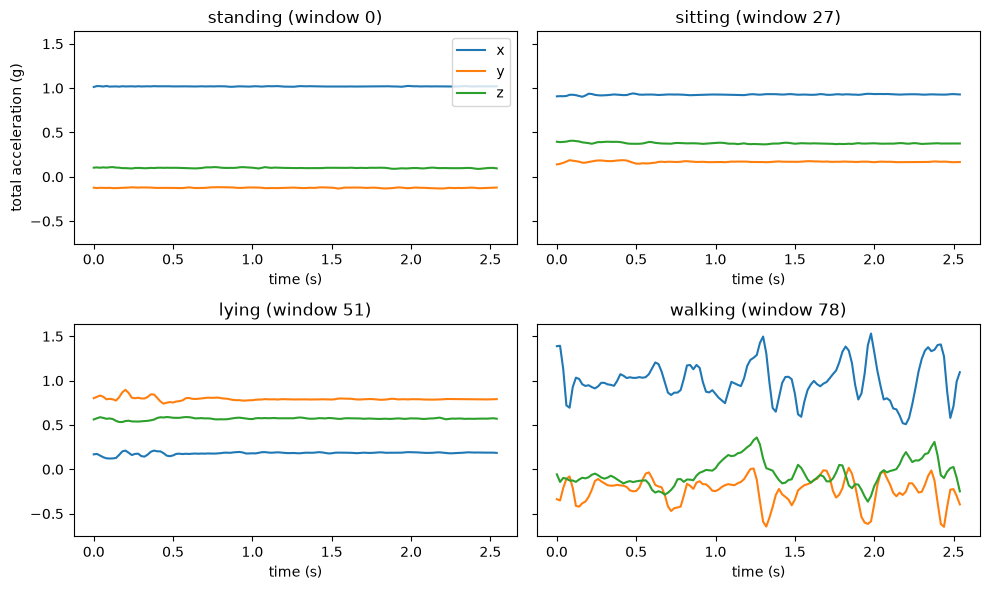

In [8]:
examples = {"standing": 0, "sitting": 27, "lying": 51, "walking": 78}

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharey=True)
for ax, (label, i) in zip(axes.flat, examples.items()):
    ax.plot(t, W[i, :, 0], label="x")
    ax.plot(t, W[i, :, 1], label="y")
    ax.plot(t, W[i, :, 2], label="z")
    ax.set_title(label + " (window " + str(i) + ")")
    ax.set_xlabel("time (s)")
axes[0, 0].set_ylabel("total acceleration (g)")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

In [9]:
gravity_x = W[:, :, 0].mean(axis=1)

body_mag = np.sqrt(W[:, :, 3]**2 + W[:, :, 4]**2 + W[:, :, 5]**2)
motion = body_mag.std(axis=1)

print(gravity_x.shape, motion.shape)

(7352,) (7352,)


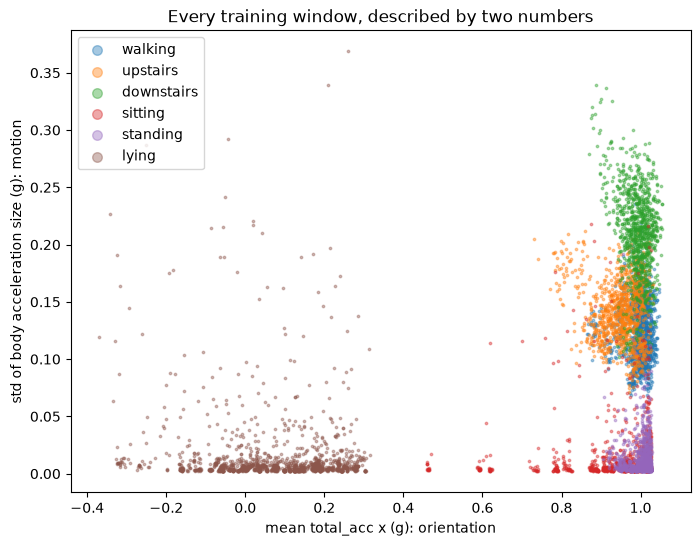

In [10]:
plt.figure(figsize=(8, 6))
for k, label in names.items():
    mask = (y == k)
    plt.scatter(gravity_x[mask], motion[mask], s=3, alpha=0.4, label=label)
plt.xlabel("mean total_acc x (g): orientation")
plt.ylabel("std of body acceleration size (g): motion")
plt.legend(markerscale=4)
plt.title("Every training window, described by two numbers")
plt.show()

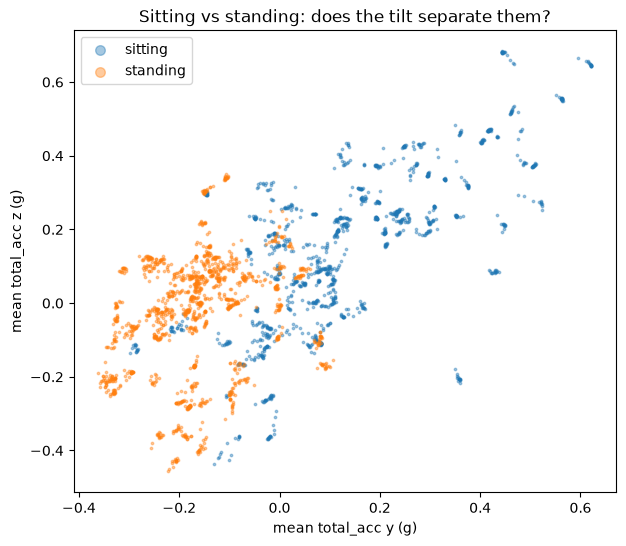

sitting average y: 0.14  average z: 0.15
standing average y: -0.16  average z: -0.03


In [ ]:
gravity_y = W[:, :, 1].mean(axis=1)
gravity_z = W[:, :, 2].mean(axis=1)

plt.figure(figsize=(7, 6))
for k in [4, 5]:
    mask = (y == k)
    plt.scatter(gravity_y[mask], gravity_z[mask], s=3, alpha=0.4, label=names[k])
plt.xlabel("mean total_acc y (g)")
plt.ylabel("mean total_acc z (g)")
plt.legend(markerscale=4)
plt.title("Sitting vs standing: does the tilt separate them?")
plt.show()

for k in [4, 5]:
    mask = (y == k)
    print(names[k], "average y:", gravity_y[mask].mean().round(2), " average z:", gravity_z[mask].mean().round(2))




# sitting and standing only differ by a small hip tilt which may not be everytime true cause people's body shape and sizes are different.

In [12]:
X = pd.read_csv(folder + "/train/X_train.txt", sep=r"\s+", header=None)

print("shape:", X.shape)
print("missing values:", X.isna().sum().sum())
print("smallest value:", X.values.min(), " largest value:", X.values.max())
print("duplicate rows:", X.duplicated().sum())

shape: (7352, 561)
missing values: 0
smallest value: -1.0  largest value: 1.0
duplicate rows: 0


       walking  upstairs  downstairs  sitting  standing  lying
row_0                                                         
1           95        53          49       47        53     50
3           58        59          49       52        61     62
5           56        47          47       44        56     52
6           57        51          48       55        57     57
7           57        51          47       48        53     52
8           48        41          38       46        54     54
11          59        54          46       53        47     57
14          59        54          45       54        60     51
15          54        48          42       59        53     72
16          51        51          47       69        78     70
17          61        48          46       64        78     71
19          52        40          39       73        73     83
21          52        47          45       85        89     90
22          46        42          36       62        63

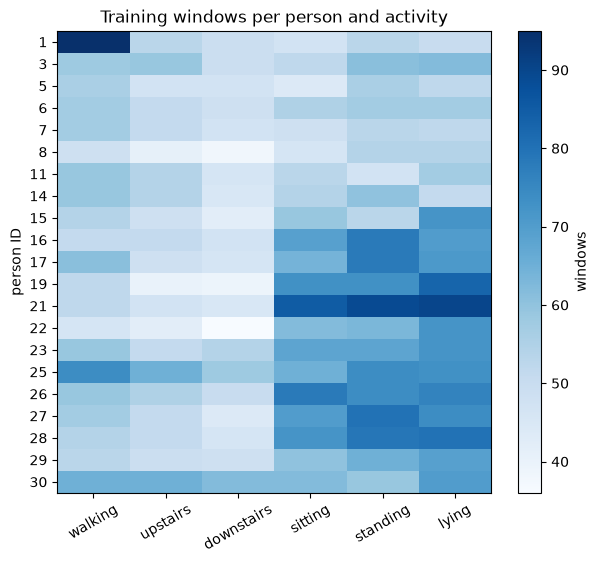

In [13]:
table = pd.crosstab(person, y)
table.columns = [names[k] for k in table.columns]
print(table)
print("windows per person: from", table.sum(axis=1).min(), "to", table.sum(axis=1).max())
print("smallest cell (one person, one activity):", table.values.min())

plt.figure(figsize=(7, 6))
plt.imshow(table.values, aspect="auto", cmap="Blues")
plt.colorbar(label="windows")
plt.xticks(range(6), table.columns, rotation=30)
plt.yticks(range(len(table)), table.index)
plt.ylabel("person ID")
plt.title("Training windows per person and activity")
plt.show()

In [ ]:
same_bout = (y[:-1] == y[1:]) & (person[:-1] == person[1:])
overlap = np.isclose(W[:-1, 64:, 0], W[1:, :64, 0]).all(axis=1)

print("neighbouring pairs from the same person and activity:", same_bout.sum())
print("of those, sharing exactly half their readings:", (same_bout & overlap).sum())

# 95.5% of neighbouring windows from the same person and activity share exactly half their readings (64 of 128), confirming the 50% overlap. 
# Windows are therefore not independent rows

neighbouring pairs from the same person and activity: 7072
of those, sharing exactly half their readings: 6752


# Module 1 summary: what the phone measures, and what the data looks like

**Data used:** only the **21 training people** (files in `train/`). The 9 test people were **not touched**. We only *looked* at data (plots, counts, checks); nothing was *fitted* or learned from it.

## Background: the sensors
- **Accelerometer:** measures gravity **plus** body movement, in **g** (1 g = strength of gravity). Even when still, it reads about 1 g on whichever axis points up, so it tells us **orientation**.
- **Gyroscope:** measures how fast the phone rotates, in rad/s.
- Recordings were cut into **windows of 2.56 seconds = 128 readings** (50 per second). Each reading has 9 channels: total acceleration (x, y, z), body acceleration (x, y, z) with gravity removed, and gyroscope (x, y, z).
- On the waist, the phone's **x axis points up** when the person is upright.

## Cell by cell

**Cell 1: imports and folder path**
- *What:* loaded NumPy (arrays), pandas (tables) and matplotlib (plots); stored the dataset path.
- *Why:* every later cell needs these.

**Cell 2: load the 9 signal files into one array `W`**
- *What:* read the 9 channel files (each 7,352 rows × 128 columns) and stacked them.
- *Result:* `W.shape = (7352, 128, 9)`, meaning **7,352 windows × 128 moments × 9 channels**.
- *Implication:* one window is a small table of 128 moments × 9 channels; `W` is all of them together.

**Cell 3: labels and people**
- *What:* loaded `y` (the activity of each window, codes 1–6) and `person` (who each window belongs to), plus a name lookup.
- *Result:* window 0 = standing (person 1), window 78 = walking (person 1).
- *Implication:* row `i` of `W`, `y` and `person` describe the **same window**. `y` is what the model will predict. `person` is never a model input, but it is essential for splitting by person later.

**Cell 4: one walking window, total = gravity + motion**
- *What:* plotted total acceleration on x, the body part, and gravity (total − body) for walking window 78, then for standing window 0.
- *Result:*
  - **Walking:** gravity is a flat line at about 1.0 g. Body motion bounces between about −0.5 and +0.5 g. The total swings between about 0.5 and 1.5 g, roughly **2 bounces per second = steps**.
  - **Standing:** everything is flat; total about 1.0 g, motion about 0.
- *Implication:* **gravity (slow) tells posture, and body motion (fast) tells movement.** The authors separated them with a filter.

**Cell 5: four activities side by side (x, y, z of total acceleration)**

| Activity | x | y | z | Meaning |
|---|---|---|---|---|
| Standing | ≈ 1.02 | ≈ −0.12 | ≈ 0.10 | upright and still |
| Sitting | ≈ 0.93 | ≈ 0.17 | ≈ 0.38 | upright, hips tilted back a little |
| Lying | ≈ 0.18 | ≈ 0.79 | ≈ 0.57 | gravity moved off x: phone horizontal |
| Walking | swings around 1.0 | bounces | bounces | upright and moving |

- *Implication:* **lying and walking are easy to recognise. Sitting vs standing differs only by a small tilt**, so it is the hardest pair.

**Cell 6: every window as two numbers (scatter plot)**
- *What:* reduced each window to 2 numbers: **orientation** (average gravity on x) and **motion** (how much the body acceleration's size varies), then plotted all 7,352 windows.
- *Result:* three groups:
  - **lying** is clearly separate (low x);
  - **sitting and standing** overlap (both upright and still);
  - **walking, upstairs and downstairs** overlap (all upright and moving; downstairs is a bit stronger).
- *Implication:* **a model can only separate what its features capture.** Separating within the groups needs features for **tilt on y and z** and **step rhythm**. That is why the dataset provides 561 features instead of 2.

**Cell 7: sitting vs standing using tilt (gravity on y and z)**
- *Result:* **partly separable.** On average, sitting has more gravity on z and y flips sign, but the clouds overlap.
- *Implication:* the information exists, so a model can get most of them right, but not all, because **people differ** (body shape, how the belt sits). It is a direct reason to **test on new people**.

**Cell 8, check 1: data quality of the 561-feature table**
- *Result:* shape **(7352, 561)**, **0 missing values**, all values between **−1 and 1**, **0 duplicate rows**.
- *Implication:* no filling-in (imputation) is needed; the authors pre-scaled the features (Part 2 looks deeper at this); no exact duplicates could leak between training and validation.

**Cell 9, check 2: windows per person and activity**
- *Result:* **every person has all six activities**; at least **36 windows** of each; **281–409 windows** per person; **downstairs** has the fewest windows.
- *Implication:* every validation fold will contain all activities. Because people contribute different amounts, we will also report **accuracy per person**, not just overall.

**Cell 10, check 3: do neighbouring windows overlap?**
- *Result:* of **7,072** neighbouring pairs from the same person and activity, **6,752 (95.5%) share exactly half their readings**. The rest are where a new bout of the same activity starts.
- *Implication:* **windows are not independent.** Neighbours are half-copies of each other, and all of a person's windows share that person's style.

## The most important conclusion: why a random split would cheat
If we shuffled all windows and split them randomly into training and testing:
- window 500 could land in training and window 501 in testing, and **half of 501 is identical to 500**;
- every test person would also appear in training, so the model would already know **their** walking style and belt tilt.

The test score would come out **too high**: it would measure "recognising windows from people it has already seen", not our question, **"does it work for a new person?"**

**So all splits in this project are made by person:** a person's windows are either all in training or all in testing, never both. That is Part 3 (evaluation design).

## Five takeaways
1. **Gravity = posture, motion = movement.** These two physical facts explain most of the data.
2. **Lying and moving vs still are easy. Sitting vs standing and walking vs stairs are the hard pairs.**
3. **Features decide what a model can see.** Better features (tilt, rhythm) are needed for the hard pairs.
4. **The data is clean:** no missing values, no duplicates, everyone did everything.
5. **Windows overlap and belong to people, so we must split by person,** or the scores will be falsely high.